<a href="https://colab.research.google.com/github/saulobortolon/Quaternios-Kalman-CC/blob/main/dominios/notebooks/X1d_reais_perseguicao.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Abrir no Colab"/></a>

# Domínio I (d): Pepé persegue Penélope num corredor

## Filtro de Kalman na reta, o sensor que não sabe o lado, e o filtro de Bayes que sabe

**Série:** [raiz](X0_raiz.ipynb) ([Colab](https://colab.research.google.com/github/saulobortolon/Quaternios-Kalman-CC/blob/main/dominios/notebooks/X0_raiz.ipynb)) · **Domínio:** [nó 1](X1_reais.ipynb) ([Colab](https://colab.research.google.com/github/saulobortolon/Quaternios-Kalman-CC/blob/main/dominios/notebooks/X1_reais.ipynb)) · **Anterior:** [X1c_reais_edo.ipynb](X1c_reais_edo.ipynb) ([Colab](https://colab.research.google.com/github/saulobortolon/Quaternios-Kalman-CC/blob/main/dominios/notebooks/X1c_reais_edo.ipynb))

**A história, reduzida a uma dimensão.** Pepé Le Gambá persegue a gatinha Penélope (a história completa, e por que o desenho é hoje considerado politicamente incorreto, está no notebook 3 da série Kalman). Agora os dois estão num **corredor reto** de 60 m. Pepé sabe onde ele mesmo está; Penélope, não. Ele precisa **estimar** onde ela está, a partir de sensores com ruído, e correr para lá.

**Os ingredientes vêm das três etapas anteriores.**
- **(a):** a interface $\boxplus$ (aqui, a soma) e os cuidados com o `float` (simetrizar a covariância).
- **(b):** a correção do filtro é um problema de mínimos quadrados, e o filtro iterado é Gauss–Newton.
- **(c):** Penélope obedece a $F=ma$ (massa, atrito viscoso, forças), e as matrizes $\mathbf F$ e $\mathbf Q$ do filtro saem da discretização exata.

**O que este notebook mostra.**
1. Com um sensor que mede a **distância com sinal** (uma "régua"), o filtro de Kalman funciona como esperado.
2. Com um sensor que mede uma **função da distância** que não distingue esquerda de direita (o "olfato"), o filtro de Kalman estendido funciona muito bem... até Pepé passar por ela. A partir daí, persegue um **fantasma**.
3. O problema não é de linearização: o filtro iterado falha igual. É de **forma**: uma gaussiana tem uma corcova só, e a crença verdadeira tem duas.
4. O **filtro de Bayes numa grade**, que guarda a crença inteira, resolve o problema. Em uma dimensão isso é barato; nos domínios seguintes não será, e é por isso que eles usam Kalman.

**Roteiro**
1. O mundo: o corredor, Penélope e Pepé
2. Os dois sensores
3. Régua + filtro de Kalman; mirar onde ela está ou onde estará
4. Olfato + EKF e IEKF: o fantasma
5. Por que falha: a crença tem duas corcovas
6. O filtro de Bayes na grade
7. O que levar deste notebook
8. Exercícios

In [1]:
# Ferramentas comuns da série (repetidas em todos os notebooks, para que cada um rode sozinho no Colab)
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=6, suppress=True)
plt.rcParams.update({"axes.grid": True, "grid.alpha": 0.3, "figure.dpi": 100,
                     "axes.spines.top": False, "axes.spines.right": False})

def confere(nome, obtido, esperado, tol=1e-9, relativo=False):
    """Compara duas quantidades. Imprime OK ou interrompe o notebook com uma mensagem clara."""
    a, b = np.asarray(obtido, dtype=float), np.asarray(esperado, dtype=float)
    escala = max(np.max(np.abs(b)), 1e-300) if relativo else 1.0
    erro = float(np.max(np.abs(a - b)) / escala)
    ok = erro <= tol
    print(f"{'OK ' if ok else 'FALHOU'}  {nome}:  diferença {'relativa ' if relativo else ''}máxima = {erro:.2e}")
    assert ok, f"conferência falhou: {nome}"

import pandas as pd
from scipy.linalg import expm
from scipy.ndimage import gaussian_filter1d
N_MC = 20            # simulações de Monte Carlo por configuração (20 → ~1,5 min no total)

---

## 1. O mundo

**O corredor** vai de 0 a 60 m, com paredes elásticas nas pontas.

**Penélope** é um bloco de massa $m=1$ kg com atrito viscoso $c=1$ N·s/m, exatamente como no notebook (c). Três forças agem sobre ela:
- uma **força aleatória** que muda suavemente, como se ela mudasse de ideia a cada segundo e pouco (um processo de Ornstein–Uhlenbeck: ruído branco filtrado, com constante de tempo de 1,5 s e desvio de 2 N);
- uma **força de fuga** de até 3 N, para longe de Pepé, quando ele está a menos de 8 m;
- a força das **paredes**, molas duras que só agem se ela tentar atravessá-las.

**Pepé** é cinemático: corre na direção do ponto em que ele **acha** que ela está, com velocidade proporcional à distância estimada e limitada a 2,5 m/s. Penélope em fuga pode chegar a 3 m/s, mais rápido que ele; Pepé só a alcança contra as paredes ou quando ela hesita.

A integração de Penélope usa a discretização exata da seção 5 do notebook (c), com as forças constantes durante cada passo de 0,05 s.

In [2]:
DT, T_FIM, L = 0.05, 60.0, 60.0
M_A, C_A = 1.0, 1.0                     # Penélope: massa e atrito viscoso
SIG_F, TAU_F = 2.0, 1.5                 # força aleatória (Ornstein–Uhlenbeck)
F_FUGA, R_FUGA = 3.0, 8.0               # força de fuga e raio em que ela percebe Pepé
K_PAREDE = 50.0
V_MAX, GANHO = 2.5, 1.5                 # Pepé: velocidade máxima e ganho de perseguição

def discretiza(A, B, dt, q=None):
    """Discretização exata (notebook c): F = e^{AΔt}, G = ∫e^{As}ds B, Q = ∫e^{As} B q Bᵀ e^{Aᵀs} ds."""
    n, m = A.shape[0], B.shape[1]
    Maug = np.zeros((n + m, n + m)); Maug[:n, :n] = A; Maug[:n, n:] = B
    E = expm(Maug * dt); F, G = E[:n, :n], E[:n, n:]
    if q is None:
        return F, G
    V = np.zeros((2 * n, 2 * n)); V[:n, :n] = -A; V[:n, n:] = B @ B.T * q; V[n:, n:] = A.T
    W = expm(V * dt); Q = F @ W[:n, n:]
    return F, G, 0.5 * (Q + Q.T)

F_PEN, G_PEN = discretiza(np.array([[0, 1.0], [0, -C_A / M_A]]), np.array([[0], [1 / M_A]]), DT)

def forca_penelope(xa, xp, f_aleatoria):
    d = xa - xp
    fuga = F_FUGA * np.sign(d) * max(0.0, 1 - abs(d) / R_FUGA)
    parede = -K_PAREDE * min(xa, 0.0) - K_PAREDE * max(xa - L, 0.0)
    return f_aleatoria + fuga + parede

def passo_mundo(ya, xp, f_al, rng):
    """Um passo de Penélope. ya = (posição, velocidade)."""
    f_al += -f_al / TAU_F * DT + SIG_F * np.sqrt(2 * DT / TAU_F) * rng.standard_normal()
    ya = F_PEN @ ya + G_PEN[:, 0] * forca_penelope(ya[0], xp, f_al)
    return ya, f_al

def passo_pepe(xp, alvo):
    return float(np.clip(xp + np.clip(GANHO * (alvo - xp), -V_MAX, V_MAX) * DT, 0.0, L))

---

## 2. Os dois sensores

Pepé mede a cada 0,1 s (10 Hz). Chamando de $d=x_A-x_P$ a distância **com sinal** de Pepé até Penélope:

- **régua:** $z=d+v$, com $v\sim\mathcal N(0,\,0{,}5^2)$. Linear, e informa o lado.
- **olfato:** $z=I(d)+v$, com $I(d)=\dfrac{1}{1+(d/\ell)^2}$, $\ell=8$ m e $v\sim\mathcal N(0,\,0{,}005^2)$. Muito preciso, mas **par**: $I(d)=I(-d)$. O cheiro diz **quão longe** ela está, nunca **de que lado**.

O gráfico mostra a intensidade e a sua derivada. A derivada é o $\mathbf H$ do filtro estendido: onde ela é grande, cada medida informa muito; onde é zero, nada. Em $d=0$ (quando Pepé está em cima dela) a derivada é zero: **o olfato fica cego exatamente na hora do encontro**.

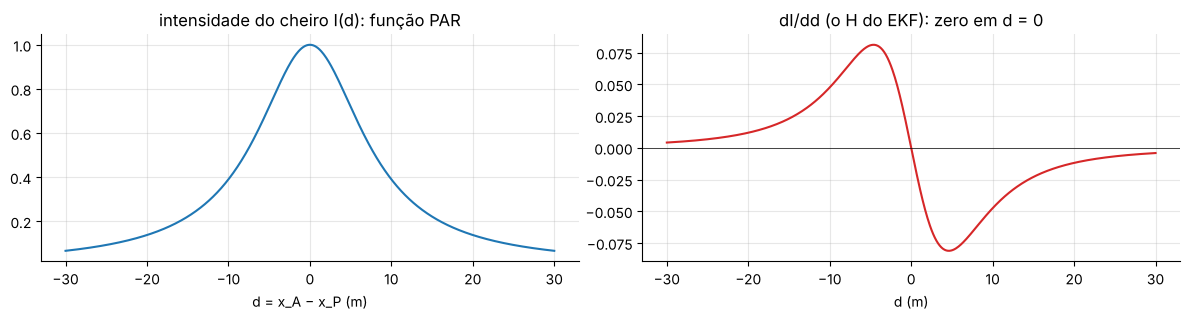

OK   a derivada analítica confere com diferenças finitas:  diferença máxima = 1.08e-10


In [3]:
ELL, SIG_I = 8.0, 0.005
SIG_REGUA, SIG_GROSSEIRA = 0.5, 3.0

def intensidade(d):   return 1.0 / (1 + (d / ELL)**2)
def d_intensidade(d): return -2 * d / ELL**2 / (1 + (d / ELL)**2)**2

dd = np.linspace(-30, 30, 601)
fig, ax = plt.subplots(1, 2, figsize=(12, 3.3))
ax[0].plot(dd, intensidade(dd)); ax[0].set_title("intensidade do cheiro I(d): função PAR")
ax[0].set_xlabel("d = x_A − x_P (m)")
ax[1].plot(dd, d_intensidade(dd), color="tab:red"); ax[1].axhline(0, color="k", lw=.5)
ax[1].set_title("dI/dd (o H do EKF): zero em d = 0"); ax[1].set_xlabel("d (m)")
plt.tight_layout(); plt.show()
confere("a derivada analítica confere com diferenças finitas",
        d_intensidade(dd), (intensidade(dd + 1e-6) - intensidade(dd - 1e-6)) / 2e-6, tol=1e-8)

---

## 3. Régua + filtro de Kalman

**O modelo do filtro.** Pepé não conhece as regras de Penélope (a força de fuga, as paredes, o ruído suavizado). Ele usa o modelo mais simples que faz sentido: velocidade quase constante, com uma **aceleração aleatória branca** de intensidade $q$. É o modelo de espaço de estados do notebook (c), com $\mathbf A=\begin{bmatrix}0&1\\0&0\end{bmatrix}$ e $\mathbf B=\begin{bmatrix}0\\1\end{bmatrix}$, e a mesma função `discretiza` dá $\mathbf F$ e $\mathbf Q$.

O estado estimado é $\hat{\mathbf x}=(\hat x_A,\hat v_A)$. Pepé conhece a própria posição $x_P$, de modo que a régua mede $z=\mathbf H\mathbf x-x_P+v$ com $\mathbf H=[1\ \ 0]$.

**Mirar onde ela está ou onde estará.** Como no IMM da série Kalman (notebook 4), Pepé pode correr para onde ela está agora, $\hat x_A$, ou para onde ela estará daqui a $\tau$ segundos, $\hat x_A+\tau\hat v_A$.

A função abaixo é a mesma para todas as configurações do notebook: muda só o filtro (KF, EKF, IEKF ou grade) e os sensores.

In [4]:
Q_INT = 1.0                                        # intensidade da aceleração aleatória do modelo
F_KF, _, Q_KF = discretiza(np.array([[0, 1.0], [0, 0]]), np.array([[0], [1.0]]), DT, Q_INT)

def correcao(x, P, z, hx, H, R):
    """Correção de Kalman para uma medida escalar."""
    S = (H @ P @ H.T).item() + R
    K = (P @ H.T)[:, 0] / S
    x = x + K * (z - hx)
    P = P - np.outer(K, H @ P)
    return x, 0.5 * (P + P.T)                       # simetrizar: a lição do notebook (a)

def correcao_olfato_iterada(x, P, z, xp, n_iter=10):
    """IEKF na forma de Bell e Cathey (Gauss–Newton, notebook b): a soma é feita sempre à predição."""
    xj = x.copy()
    for _ in range(n_iter):
        d = xj[0] - xp; H = np.array([[d_intensidade(d), 0.0]])
        S = (H @ P @ H.T).item() + SIG_I**2; K = (P @ H.T)[:, 0] / S
        x_novo = x + K * (z - intensidade(d) - (H @ (x - xj)).item())
        if np.linalg.norm(x_novo - xj) < 1e-10:
            xj = x_novo; break
        xj = x_novo
    d = xj[0] - xp; H = np.array([[d_intensidade(d), 0.0]])
    S = (H @ P @ H.T).item() + SIG_I**2; K = (P @ H.T)[:, 0] / S
    P = P - np.outer(K, H @ P)
    return xj, 0.5 * (P + P.T)

# ---------------- filtro de Bayes numa grade (seção 6) ----------------
XG = np.arange(-5.0, 65.0 + 1e-9, 0.1)             # posições de Penélope
VG = np.arange(-6.0, 6.0 + 1e-9, 0.25)             # velocidades
def grade_inicial(x0, s0):
    B = np.outer(np.exp(-0.5 * (VG / 2.0)**2), np.exp(-0.5 * ((XG - x0) / s0)**2)); return B / B.sum()
def grade_predicao(B, dt):
    out = np.empty_like(B)
    for i, v in enumerate(VG):                       # cada linha de velocidade desloca a crença em x
        out[i] = np.interp(XG - v * dt, XG, B[i], left=0, right=0)
    out = gaussian_filter1d(out, np.sqrt(Q_INT * dt) / (VG[1] - VG[0]), axis=0, mode="constant")  # aceleração aleatória
    return out / out.sum()
def grade_correcao(B, verossimilhanca_x):
    B = B * verossimilhanca_x[None, :]; return B / B.sum()

def simula(cfg, seed, guarda_grade=False):
    """cfg: filtro ('kf', 'ekf', 'iekf' ou 'grade'), sensores, tau, mira ('moda' ou 'media'), x0."""
    rng = np.random.default_rng(seed)
    ya, xp, f_al = np.array([40.0, 0.0]), 30.0, 0.0
    x0, s0 = cfg.get("x0", 40.0 + 3 * rng.standard_normal()), 5.0
    x, P = np.array([x0, 0.0]), np.diag([s0**2, 2.0**2])
    grade = cfg["filtro"] == "grade"
    if grade:
        B = grade_inicial(x0, s0)
    reg = {k: [] for k in ["t", "xa", "xp", "xh", "sd", "nees"]}; imagens = []
    for k in range(int(T_FIM / DT)):
        ya, f_al = passo_mundo(ya, xp, f_al, rng)
        if not grade:
            x = F_KF @ x; P = F_KF @ P @ F_KF.T + Q_KF
        if k % 2 == 1:                                         # medidas a 10 Hz
            if grade:
                B = grade_predicao(B, 2 * DT)
            d_ver = ya[0] - xp
            for s in cfg["sensores"]:
                if s == "grosseira" and k % 20 != 19:          # a régua grosseira só mede a 1 Hz
                    continue
                if s in ("regua", "grosseira"):
                    sig = SIG_REGUA if s == "regua" else SIG_GROSSEIRA
                    z = d_ver + sig * rng.standard_normal()
                    if grade:
                        B = grade_correcao(B, np.exp(-0.5 * ((z - (XG - xp)) / sig)**2))
                    else:
                        x, P = correcao(x, P, z, x[0] - xp, np.array([[1.0, 0.0]]), sig**2)
                elif s == "olfato":
                    z = intensidade(d_ver) + SIG_I * rng.standard_normal()
                    if grade:
                        B = grade_correcao(B, np.exp(-0.5 * ((z - intensidade(XG - xp)) / SIG_I)**2))
                    elif cfg["filtro"] == "iekf":
                        x, P = correcao_olfato_iterada(x, P, z, xp)
                    else:
                        d = x[0] - xp
                        x, P = correcao(x, P, z, intensidade(d), np.array([[d_intensidade(d), 0.0]]), SIG_I**2)
        if grade:
            mx = B.sum(0)
            xh = XG[np.argmax(gaussian_filter1d(mx, 3))] if cfg.get("mira", "moda") == "moda" else mx @ XG
            vh = B.sum(1) @ VG; sd = np.sqrt(mx @ (XG - mx @ XG)**2)
            if guarda_grade and k % 2 == 1:
                imagens.append((k * DT, mx[XG > xp].sum(), float(ya[0] > xp)))
        else:
            xh, vh, sd = x[0], x[1], np.sqrt(P[0, 0])
        xp = passo_pepe(xp, xh + cfg.get("tau", 0.0) * vh)
        e = np.array([ya[0] - xh, ya[1] - vh])
        reg["t"].append((k + 1) * DT); reg["xa"].append(ya[0]); reg["xp"].append(xp); reg["xh"].append(xh); reg["sd"].append(sd)
        reg["nees"].append(e @ np.linalg.solve(P, e) if not grade else np.nan)
    out = {k: np.array(v) for k, v in reg.items()}
    if guarda_grade:
        out["grade"] = imagens
    return out

def metricas(h):
    e, d = np.abs(h["xa"] - h["xh"]), np.abs(h["xa"] - h["xp"])
    k0 = int(5 / DT)
    return {"perdeu o rastro": bool((e[-int(10 / DT):] > 5).mean() > 0.9),      # erro > 5 m nos últimos 10 s
            "erro mediano (m)": np.median(e[k0:]),
            "tempo perto dela (< 1 m)": np.mean(d[k0:] < 1.0),
            "encontros": int(np.sum((d[1:] < 0.5) & (d[:-1] >= 0.5))),
            "dentro de ±2σ": np.mean(e[k0:] < 2 * h["sd"][k0:])}

def monte_carlo(configs, n=N_MC):
    tab = {}
    for nome, cfg in configs.items():
        d = pd.DataFrame([metricas(simula(cfg, 100 + r)) for r in range(n)])
        tab[nome] = {"perdeu o rastro": f"{d['perdeu o rastro'].sum()} de {n}",
                     **{k: d[k].median() for k in ["erro mediano (m)", "tempo perto dela (< 1 m)", "encontros", "dentro de ±2σ"]}}
    return pd.DataFrame(tab).T

def desenha(h, titulo, ax):
    ax.plot(h["t"], h["xa"], "k", lw=1.5, label="Penélope (verdade)")
    ax.plot(h["t"], h["xp"], color="tab:purple", lw=1.2, label="Pepé")
    ax.plot(h["t"], h["xh"], color="tab:orange", lw=1, label="estimativa de Pepé")
    ax.fill_between(h["t"], h["xh"] - 2 * h["sd"], h["xh"] + 2 * h["sd"], color="tab:orange", alpha=.2, label="± 2σ")
    ax.axhspan(-20, 0, color="gray", alpha=.15); ax.axhspan(L, 90, color="gray", alpha=.15)
    ax.set_ylim(-10, 70); ax.set_title(titulo, fontsize=10); ax.set_xlabel("t (s)"); ax.set_ylabel("posição no corredor (m)")

**Conferências antes de simular.** Três propriedades que o código precisa ter:
- o $\mathbf Q$ da discretização exata coincide com a fórmula fechada do modelo de velocidade constante, $q\begin{bmatrix}\Delta t^3/3&\Delta t^2/2\\\Delta t^2/2&\Delta t\end{bmatrix}$ (exercício 5 do notebook c);
- com uma medida **linear**, o IEKF para na primeira iteração e dá exatamente o filtro de Kalman (notebook b);
- quando a crença é gaussiana (régua, sem ambiguidade), o filtro de Bayes na grade concorda com o filtro de Kalman, a menos da discretização da grade.

In [5]:
confere("Q exato = fórmula do modelo de velocidade constante", Q_KF,
        Q_INT * np.array([[DT**3 / 3, DT**2 / 2], [DT**2 / 2, DT]]), tol=1e-15)

# IEKF com medida linear = KF (uma iteração de Gauss–Newton basta)
x_t, P_t, z_t, xp_t = np.array([42.0, 0.5]), np.diag([4.0, 1.0]), 11.3, 30.0
H_lin = np.array([[1.0, 0.0]])
x_kf, P_kf = correcao(x_t, P_t, z_t, x_t[0] - xp_t, H_lin, 0.25)
xj = x_t.copy()
for _ in range(5):
    xj = x_t + (P_t @ H_lin.T)[:, 0] / ((H_lin @ P_t @ H_lin.T).item() + 0.25) * (z_t - (xj[0] - xp_t) - (H_lin @ (x_t - xj)).item())
confere("IEKF com medida linear = KF", xj, x_kf, tol=1e-12)

# grade = KF quando a crença é gaussiana: 3 s de medidas da régua, com Pepé parado
rng_t = np.random.default_rng(0)
x, P = np.array([40.0, 0.0]), np.diag([5.0**2, 2.0**2]); B = grade_inicial(40.0, 5.0)
xa_t = 41.0
for k in range(30):
    x = F_KF @ F_KF @ x; P = F_KF @ F_KF @ P @ F_KF.T @ F_KF.T + F_KF @ Q_KF @ F_KF.T + Q_KF
    B = grade_predicao(B, 2 * DT)
    z = xa_t - 30.0 + SIG_REGUA * rng_t.standard_normal()
    x, P = correcao(x, P, z, x[0] - 30.0, H_lin, SIG_REGUA**2)
    B = grade_correcao(B, np.exp(-0.5 * ((z - (XG - 30.0)) / SIG_REGUA)**2))
mx = B.sum(0); media_g = mx @ XG; dp_g = np.sqrt(mx @ (XG - media_g)**2)
print(f"KF: média {x[0]:.4f}, desvio {np.sqrt(P[0, 0]):.4f}   |   grade: média {media_g:.4f}, desvio {dp_g:.4f}")
confere("grade = KF (média da posição)", media_g, x[0], tol=0.01)
confere("grade = KF (desvio da posição)", dp_g, np.sqrt(P[0, 0]), tol=0.05, relativo=True)

OK   Q exato = fórmula do modelo de velocidade constante:  diferença máxima = 0.00e+00
OK   IEKF com medida linear = KF:  diferença máxima = 0.00e+00
KF: média 40.9214, desvio 0.2736   |   grade: média 40.9182, desvio 0.2761
OK   grade = KF (média da posição):  diferença máxima = 3.14e-03
OK   grade = KF (desvio da posição):  diferença relativa máxima = 9.44e-03


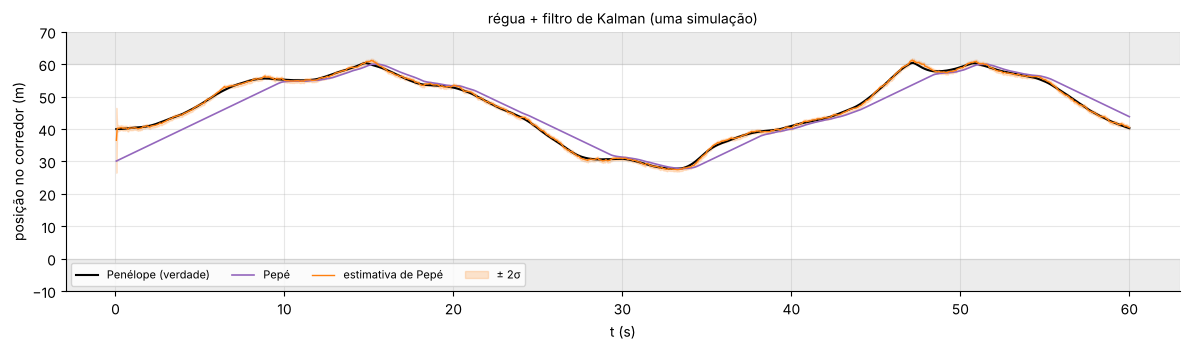

NEES médio depois de 5 s: 2.68  (ideal: 2, a dimensão do estado)


,perdeu o rastro,erro mediano (m),tempo perto dela (< 1 m),encontros,dentro de ±2σ
"régua + KF, mira onde ela está",0 de 20,0.212427,0.22,5.0,0.928182
"régua + KF, mira onde ela estará (τ = 0,8 s)",0 de 20,0.220642,0.319545,8.5,0.906818


In [6]:
fig, ax = plt.subplots(figsize=(12, 3.6))
h = simula({"filtro": "kf", "sensores": ["regua"]}, 100)
desenha(h, "régua + filtro de Kalman (uma simulação)", ax); ax.legend(fontsize=8, ncol=5, loc="lower left")
plt.tight_layout(); plt.show()
print(f"NEES médio depois de 5 s: {np.mean(h['nees'][100:]):.2f}  (ideal: 2, a dimensão do estado)")

tab_regua = monte_carlo({"régua + KF, mira onde ela está": {"filtro": "kf", "sensores": ["regua"]},
                         "régua + KF, mira onde ela estará (τ = 0,8 s)": {"filtro": "kf", "sensores": ["regua"], "tau": 0.8}})
tab_regua.round(3)

**Leitura.** Com a régua, o filtro nunca perde Penélope; o erro mediano fica em torno de 20 cm, bem abaixo do ruído da própria régua (50 cm), porque o filtro combina muitas medidas com o modelo de movimento. A faixa de $\pm2\sigma$ cobre o erro em cerca de 90% do tempo, um pouco abaixo dos 95% ideais: o modelo de "velocidade quase constante" é mais simples que a Penélope real (que foge de Pepé e quica nas paredes), e o filtro fica levemente otimista. **Mirar onde ela estará** aumenta o tempo que Pepé passa perto dela e o número de encontros: prever é útil, como no notebook 4 da série Kalman.

---

## 4. Olfato + EKF e IEKF: o fantasma

Agora Pepé só tem o olfato. A medida é não linear, $z=I(\hat x_A-x_P)$, e o EKF a lineariza em torno da estimativa: $\mathbf H=[\,I'(\hat x_A-x_P)\ \ 0\,]$. O IEKF repete a linearização até convergir (Gauss–Newton, notebook b).

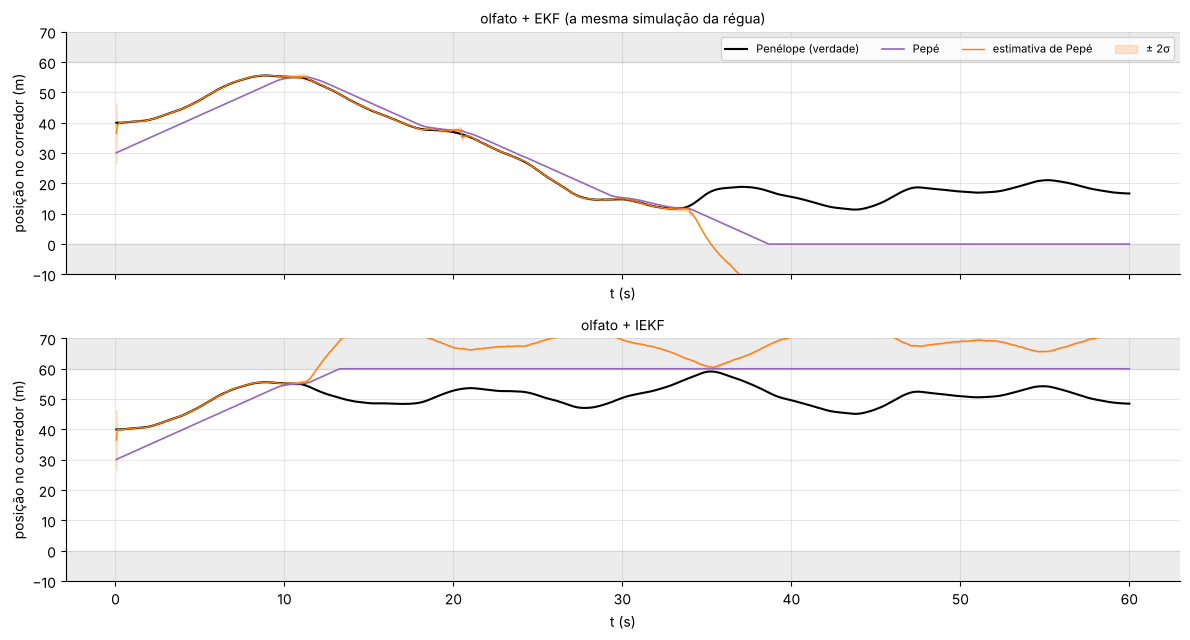

,perdeu o rastro,erro mediano (m),tempo perto dela (< 1 m),encontros,dentro de ±2σ
olfato + EKF,20 de 20,34.58864,0.031818,1.0,0.122273
olfato + IEKF,20 de 20,32.091936,0.030909,1.0,0.116818
"olfato + régua grosseira (σ = 3 m, 1 Hz) + EKF",19 de 20,53.253391,0.034545,1.0,0.148182


In [7]:
fig, axs = plt.subplots(2, 1, figsize=(12, 6.5), sharex=True)
desenha(simula({"filtro": "ekf", "sensores": ["olfato"]}, 100), "olfato + EKF (a mesma simulação da régua)", axs[0])
desenha(simula({"filtro": "iekf", "sensores": ["olfato"]}, 100), "olfato + IEKF", axs[1])
axs[0].legend(fontsize=8, ncol=5, loc="upper right"); plt.tight_layout(); plt.show()

tab_olfato = monte_carlo({"olfato + EKF": {"filtro": "ekf", "sensores": ["olfato"]},
                          "olfato + IEKF": {"filtro": "iekf", "sensores": ["olfato"]},
                          "olfato + régua grosseira (σ = 3 m, 1 Hz) + EKF": {"filtro": "ekf", "sensores": ["olfato", "grosseira"]}})
tab_olfato.round(3)

**Leitura.**
- Durante o primeiro meio minuto, o EKF com olfato é **melhor** que a régua: erro de poucos centímetros, porque o olfato é muito preciso.
- Então Pepé **passa por ela** ($d$ troca de sinal). Nesse instante, $I'(d)\approx0$ e o olfato não informa nada; a estimativa atravessa ou não atravessa o zero junto com a verdade, conforme a sorte. Quando não atravessa, ela passa a ser o **reflexo** de Penélope em relação a Pepé, e a medida continua perfeitamente compatível com esse reflexo, porque $I(d)=I(-d)$. Pepé corre atrás do fantasma até a parede, e a estimativa sai do corredor.
- O IEKF falha do mesmo jeito: iterar melhora a **linearização**, mas o problema não é de linearização.
- Uma **régua grosseira** (desvio de 3 m, uma vez por segundo), que bastaria para dizer o lado, quase não ajuda. Depois da troca, o filtro está **confiante** no lado errado (desvio de 10 a 20 cm), e uma medida que discorda em 20 m com desvio de 3 m é tratada como um ruído improvável: o ganho é minúsculo. A coluna "dentro de ±2σ" (12% a 15%, contra 95% ideais) mostra o tamanho do excesso de confiança.

Esses números, e a figura, contam uma história que vale a pena guardar: **um filtro de Kalman não sabe que está errado**. A covariância dele só mede a incerteza **dentro** da hipótese que ele escolheu.

---

## 5. Por que falha: a crença tem duas corcovas

Pense no que a regra de Bayes diria. Antes de Pepé chegar perto, a crença está de um lado só. Quando ele passa por ela, as medidas do olfato são igualmente compatíveis com "ela continua à frente" e "ela ficou para trás". A crença honesta passa a ter **duas corcovas**, uma em cada lado de Pepé, e as medidas seguintes só podem desfazer o empate por meios indiretos:
- **o movimento de Pepé:** a hipótese "fantasma" exige que Penélope acelere exatamente como o reflexo dos movimentos dele, o que o modelo considera improvável. Com o tempo, a hipótese verdadeira ganha peso;
- **outro sensor**, como a régua grosseira, que informa o lado diretamente.

Um filtro de Kalman só representa **uma** gaussiana. Na troca de lado, ele é obrigado a escolher uma corcova, e escolhe sem saber que escolheu. É a limitação que a série Kalman discutiu no IMM (notebook 4), lá com modos de movimento e aqui com hipóteses de posição.

## 6. O filtro de Bayes na grade

Em uma dimensão, dá para fazer a conta de Bayes **literalmente**, como na seção 2 do notebook 5 da série Kalman. A crença sobre $(x_A,v_A)$ é guardada numa grade de 701 posições × 49 velocidades:
- **predição:** cada linha de velocidade desloca a crença em $x$ por $v\Delta t$, e a aceleração aleatória espalha a crença em $v$ (uma convolução);
- **correção:** a crença é multiplicada pela verossimilhança da medida, $p(z\mid x_A)$, e renormalizada.

**Onde Pepé deve mirar.** Com duas corcovas, a **média** da crença fica entre elas, onde Penélope certamente **não** está. Pepé mira na **moda**, o pico mais alto. A tabela abaixo inclui a mira na média, para comparar.

A primeira célula desenha a crença ao longo do tempo, na mesma simulação das figuras anteriores. A segunda faz o Monte Carlo.

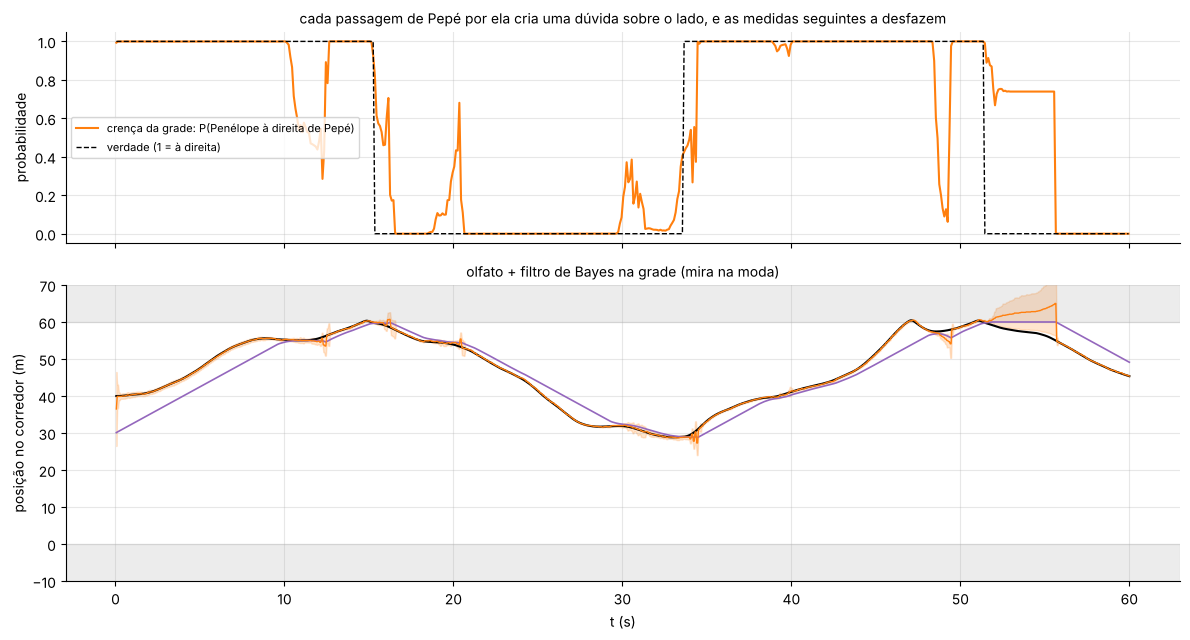

In [8]:
h = simula({"filtro": "grade", "sensores": ["olfato"]}, 100, guarda_grade=True)
tg, p_dir, lado = np.array(h["grade"]).T
fig, axs = plt.subplots(2, 1, figsize=(12, 6.5), sharex=True, gridspec_kw={"height_ratios": [1, 1.4]})
axs[0].plot(tg, p_dir, color="tab:orange", label="crença da grade: P(Penélope à direita de Pepé)")
axs[0].plot(tg, lado, "k--", lw=1, label="verdade (1 = à direita)")
axs[0].set_ylim(-0.05, 1.05); axs[0].set_ylabel("probabilidade"); axs[0].legend(fontsize=8, loc="center left")
axs[0].set_title("cada passagem de Pepé por ela cria uma dúvida sobre o lado, e as medidas seguintes a desfazem", fontsize=10)
desenha(h, "olfato + filtro de Bayes na grade (mira na moda)", axs[1])
plt.tight_layout(); plt.show()

**Leitura da figura.** No painel de cima, a linha tracejada é a verdade: em que lado de Pepé Penélope está. A curva laranja é o que o filtro em grade acredita. Longe dos encontros, ela é 0 ou 1: o filtro tem certeza do lado. A cada passagem de Pepé por ela, a crença se divide entre os dois lados (a curva sai dos extremos): é o **fantasma**, a segunda corcova espelhada. O filtro carrega as duas hipóteses e deixa as medidas seguintes decidirem; em geral, em poucos segundos a crença volta para o lado certo. O EKF, nesse mesmo instante, teria sido obrigado a escolher um lado.

Repare no episódio entre 51 e 56 s: Pepé está **parado** contra a parede, e a dúvida demora uns 4 segundos para se desfazer, muito mais que nas outras passagens. Sem o movimento dele, as duas hipóteses continuam igualmente compatíveis com o cheiro; assim que ele volta a andar, a hipótese errada morre. **O movimento do perseguidor também é informação**, uma ideia que tem nome: *sensoriamento ativo*.

In [9]:
tab_grade = monte_carlo({"olfato + grade (mira na moda)": {"filtro": "grade", "sensores": ["olfato"]},
                         "olfato + grade (mira na MÉDIA)": {"filtro": "grade", "sensores": ["olfato"], "mira": "media"},
                         "olfato + régua grosseira + grade": {"filtro": "grade", "sensores": ["olfato", "grosseira"]}})
pd.concat([tab_regua, tab_olfato, tab_grade]).drop(columns=["dentro de ±2σ"]).round(3)

,perdeu o rastro,erro mediano (m),tempo perto dela (< 1 m),encontros
"régua + KF, mira onde ela está",0 de 20,0.212427,0.22,5.0
"régua + KF, mira onde ela estará (τ = 0,8 s)",0 de 20,0.220642,0.319545,8.5
olfato + EKF,20 de 20,34.58864,0.031818,1.0
olfato + IEKF,20 de 20,32.091936,0.030909,1.0
"olfato + régua grosseira (σ = 3 m, 1 Hz) + EKF",19 de 20,53.253391,0.034545,1.0
olfato + grade (mira na moda),0 de 20,0.092618,0.187727,4.0
olfato + grade (mira na MÉDIA),0 de 20,0.103239,0.172273,4.0
olfato + régua grosseira + grade,0 de 20,0.093456,0.213182,5.0


**Leitura.**
- Com o **mesmo olfato** que derrubou o EKF em todas as simulações, o filtro em grade **não perdeu Penélope em nenhuma** das 20, e o erro mediano (cerca de 9 cm) é menor que o da régua. Com a régua grosseira, Pepé passa ainda mais tempo perto dela.
- **Mirar na média** de uma crença com duas corcovas é mirar no lugar onde ela não está. Aqui o preço foi pequeno (um pouco menos de tempo perto dela), porque os fantasmas duram poucos segundos; com duas hipóteses que persistissem, seria grave.
- **Uma ressalva de justiça:** a grade tem um tamanho finito (de −5 a 65 m), o que lhe dá uma noção vaga de onde termina o mundo, coisa que o EKF não tem. Num teste feito durante a preparação deste notebook, uma versão da grade que conhecia as paredes explicitamente deu o mesmo resultado; o exercício 3 pede para alargar a grade. O que a salva é carregar as duas hipóteses.

**O custo.** O filtro em grade faz, a cada medida, contas com 34 mil números; o EKF, com 6. Em uma dimensão, isso é barato. No domínio II (o plano), a grade teria $701^2\times49^2\approx10^9$ células, e no domínio VIII (posição, velocidade e atitude no espaço) seria inimaginável. É por isso que os domínios seguintes voltam ao Kalman, e tratam a ambiguidade com outras ferramentas: **vários filtros em paralelo** (como no IMM), sensores que quebram a simetria, ou **filtros de partículas**, que são grades que só gastam pontos onde a crença é grande.

---

## 7. O que levar deste notebook

1. **O filtro de Kalman é um filtro de Bayes com crença gaussiana.** Quando a crença verdadeira é parecida com uma gaussiana (a régua), ele é ótimo e barato.
2. **Um sensor simétrico cria crenças com várias corcovas.** O olfato não sabe o lado; em duas e três dimensões, um sensor de distância não sabe a direção, e uma câmera não sabe a profundidade. A mesma doença reaparece em todos os domínios.
3. **Iterar não cura um problema de forma.** O IEKF melhora a linearização, mas continua com uma só hipótese.
4. **Um filtro confiante ignora quem discorda dele.** A covariância pequena, depois da troca de lado, fez a régua grosseira parecer ruído.
5. **Mire na moda, não na média,** quando a crença pode ter várias corcovas.

**Próximo domínio:** ℝ², o plano ([nó do domínio II](X2_vetores2d.ipynb) ([Colab](https://colab.research.google.com/github/saulobortolon/Quaternios-Kalman-CC/blob/main/dominios/notebooks/X2_vetores2d.ipynb))). Pepé e Penélope ganham mais uma direção, o olfato vira um gradiente, e a ambiguidade de "lado" vira uma ambiguidade de "direção".

---

## 8. Exercícios

1. **Ajustar o modelo.** Mude `Q_INT` (a aceleração aleatória do modelo) para 0,3 e para 3 na configuração régua + KF. O que acontece com o erro e com a cobertura de $\pm2\sigma$? Existe um valor que deixa a cobertura em 95%?
2. **Pepé mais esperto.** Na configuração olfato + EKF, faça Pepé **parar** de correr quando a distância estimada for menor que 2 m, em vez de passar por cima dela. O número de simulações em que ele perde o rastro diminui? Por quê?
3. **A grade sem paredes.** Em `simula`, aumente a grade para $[-60, 120]$ m. O filtro em grade continua a funcionar? (Isso confirma a ressalva de justiça da seção 6.)
4. **Dois EKFs espelhados.** Rode dois EKFs em paralelo, um para cada lado, e pese-os pela verossimilhança das inovações, como no IMM. Quando a distância estimada passar perto de zero, recrie o filtro espelhado. Compare com o filtro em grade, em acerto e em tempo de cálculo.
5. **O custo da grade.** Meça o tempo de `simula` com filtro em grade e com EKF. Estime quanto tempo levaria uma grade no plano com a mesma resolução.